# Notebook 01 — Designing the environment

In notebook 00 we built a car that drives where we tell it to. Now we build the **world it lives
in**: goal objects, obstacles, random layouts, and the rules for success and failure.

This is one of the most important parts of the whole project, and the most underrated. **A model
can only learn what the data and the environment teach it.** If every episode puts the goal straight
ahead, the model learns "drive forward" and never learns to find things. If the only red object is
always the goal, it learns "drive to red" and ignores the word "sphere". Environment design is how
we prevent these shortcuts *before* any training happens.

**What you will learn here**
1. The vocabulary of RL environments: observation, action, episode, reset/step, terminated/truncated.
2. How we generate random but *always solvable* episodes, and why each design rule exists.
3. Planning on a grid: occupancy maps, inflation, shortest paths and *geodesic* distance.
4. How to check that a randomly generated "training distribution" has no hidden biases.
5. How success and collisions are detected, verified with a scripted *expert* driver.

## 1. Setup
Same as notebook 00: make the `carsim` package importable and set up plotting.

In [1]:
import sys, time, math
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"; RUNS.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. What is an "environment"?

In reinforcement learning (and in our imitation-learning data collection), everything outside the
"brain" is the **environment**. The brain (you with the keyboard, or later the neural network,
called the **policy**) and the environment talk in a loop:

```
          observation (camera image + car speed)
   ┌──────────────────────────────────────────────┐
   │                                              ▼
 Environment                                   Policy
 (simulator)                              (you / the network)
   ▲                                              │
   └──────────────────────────────────────────────┘
              action (vx, vy, wz)   ... 10 times per second
```

| Term | In our project |
|---|---|
| **Observation** | What the policy sees: the 256×256 FPV image + the car's measured speed (vx, vy, wz). Plus the text prompt, which is fixed for the whole episode. |
| **Action** | What the policy outputs: (vx, vy, wz), held for 0.1 s. |
| **Episode** | One attempt at one task: start somewhere, try to reach the goal. |
| **`reset()`** | Start a new episode: new layout, new goal, new prompt. |
| **`step(action)`** | Apply an action for 0.1 s and return the new observation. |
| **terminated** | The episode ended *because of the task*: here, success. |
| **truncated** | The episode was cut off *for an external reason*: here, the 60 s time limit. |
| **info** | Extra diagnostics the policy must **not** see: true position, distance to goal, collisions… We use them for rewards, metrics and plots. |

Why separate *terminated* and *truncated*? In RL it matters later: after success the future is
over, but after a timeout the car *could* have continued, and the learning maths treats these two
cases differently. Our `NavEnv` class follows the same interface as **Gymnasium**, the standard RL
library, so the concepts carry over to any RL tutorial you read.

## 3. Design rules (and the shortcut each one prevents)

| Rule | Why | Shortcut it prevents |
|---|---|---|
| 3 shapes × 6 colours of goal objects; 3–6 objects per episode | The prompt must actually select one of several candidates | "Drive to the only object" |
| **Half the episodes include a distractor sharing one word** with the goal (e.g. a *red cube* next to the *red sphere*) | The model must understand both words | "Drive to whatever is red" |
| Obstacles only in neutral greys/whites | A colour word always refers to a goal object | Confusing obstacles with goals |
| Random positions; goal **visible at the start in 50%** of episodes, behind or beside the car in the other 50% | Teaches searching (turning to look) | "Always drive straight ahead" |
| The goal is not always the first object in the list | Code-level hygiene | Accidental index leaks |
| Several phrasings ("go to", "find", "head to"…) and synonyms ("ball", "block") | Language robustness | Memorising one exact sentence |
| Random floor, wall colour and lighting | Robust vision | Memorising one exact look |
| **Every episode is checked to be solvable** | Unsolvable episodes teach nothing and corrupt metrics | — |
| Every episode is reproducible from one integer **seed** | We can rebuild any episode exactly, e.g. one from the dataset | — |

## 4. The vocabulary: goal objects and prompts

Below are the 6 colours × 3 shapes and a few randomly generated prompts. The shape words have
synonyms: a sphere may be called a "ball", a cube a "block". This forces the model to learn that
several words can mean the same thing.

In [2]:
from carsim.world import (SHAPES, COLORS, SHAPE_WORDS, PROMPT_TEMPLATES, OBSTACLE_POOL, EnvConfig,
                          sample_episode, Grid, occupancy, geodesic_field, shortest_path)
print("Shapes :", SHAPES)
print("Colours:", list(COLORS))
print("Synonyms:", SHAPE_WORDS)
print("\nTen random prompts:")
for s in range(10):
    print("  ", sample_episode(s).prompt)

Shapes : ('sphere', 'cube', 'cylinder')
Colours: ['red', 'green', 'blue', 'yellow', 'purple', 'orange']
Synonyms: {'sphere': ['sphere', 'ball'], 'cube': ['cube', 'block'], 'cylinder': ['cylinder']}

Ten random prompts:
   go find the yellow cube
   drive to the purple block
   go find the red ball
   go to the green ball
   navigate to the orange cylinder
   go to the red cylinder
   navigate to the yellow cube
   go to the purple block
   move to the green sphere
   move to the orange cylinder


## 5. Generating one episode, step by step

`sample_episode(seed)` in `carsim/world.py` does the following (pure numpy, no simulator):

1. **Pick the goal and distractors.** With probability 0.5, add distractor(s) that share exactly
   one word with the goal.
2. **Place objects and 5–15 obstacles** at random positions, rejecting overlaps (15 cm minimum gap).
3. **Check reachability** and compute the distance-to-goal map (section 6).
4. **Pick a start pose**: reachable, at least 2 m from the goal, and facing toward the goal
   (±20°) or away from it (60–300°), depending on the coin flip for visibility.
5. **Write the prompt** and pick floor, wall and lighting variations.

**How to read the maps below:** grey shapes = obstacles; coloured = goal objects (● sphere,
■ cube, ⬢ cylinder); the white **★** marks the goal; the dashed circle around it is the
**success zone**; the black arrow is the car's start pose with its camera field of view in yellow;
the dotted red line is the shortest safe path.

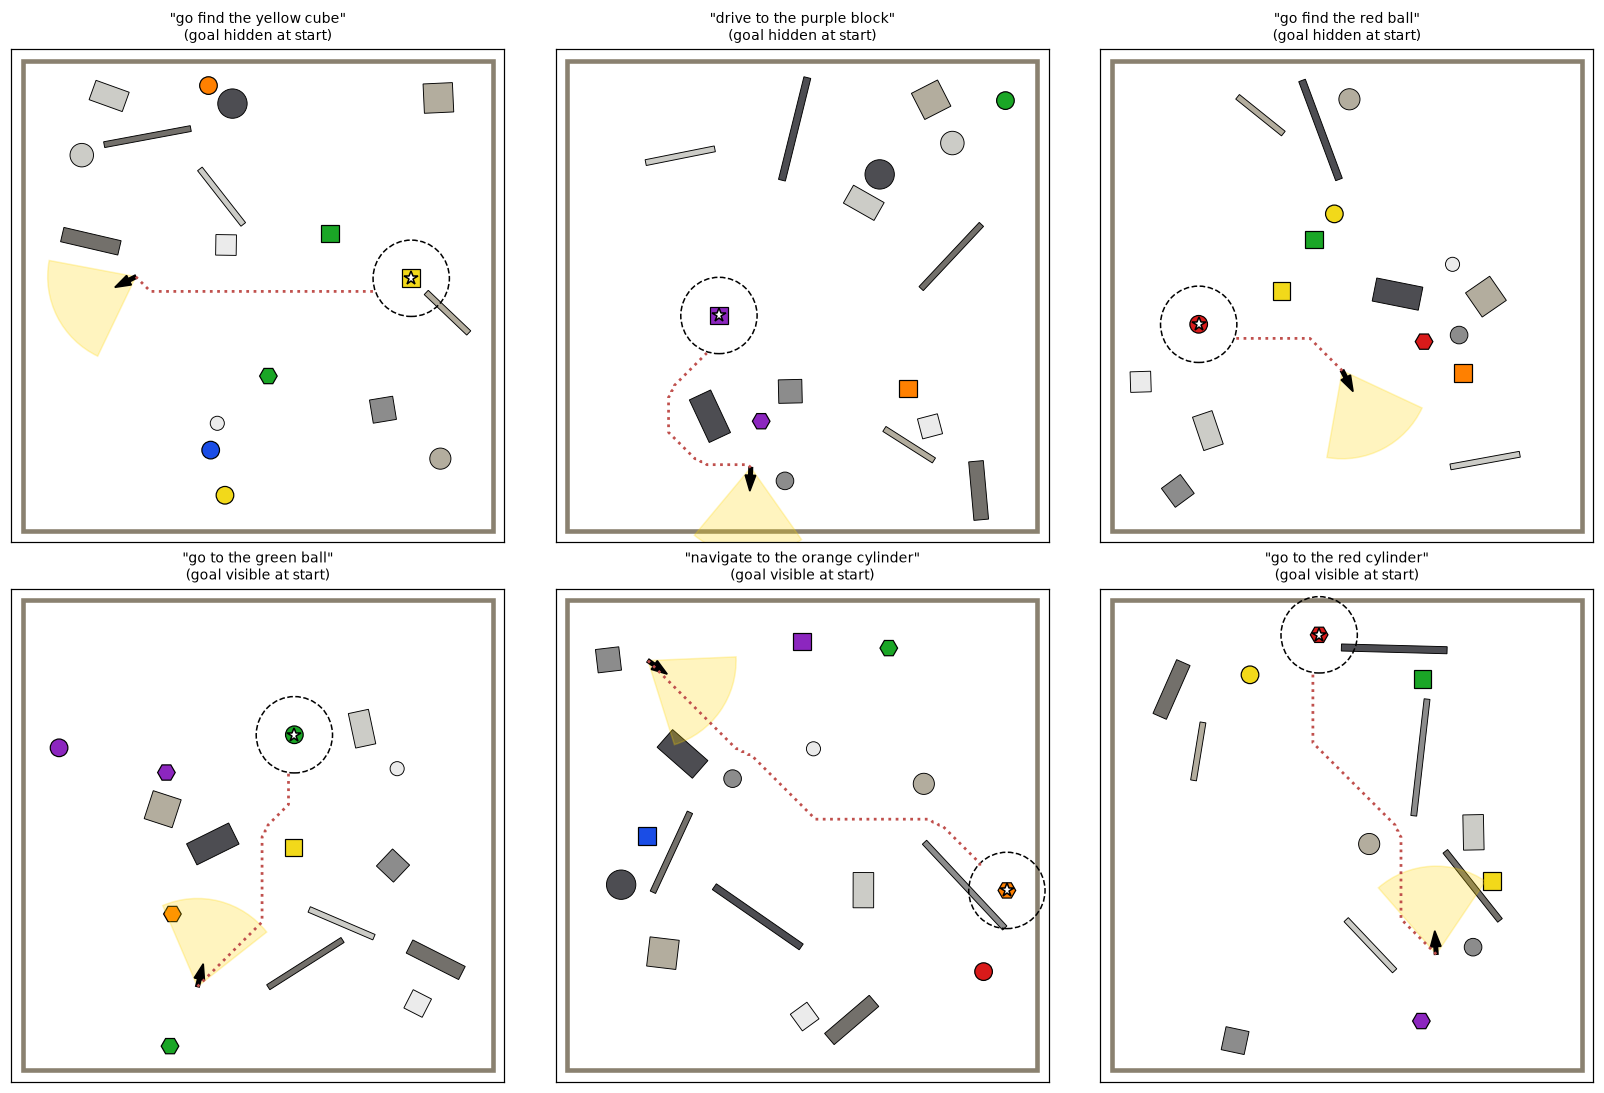

In [3]:
from carsim.viz import draw_episode
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for k, ax in enumerate(axes.flat):
    draw_episode(sample_episode(k), ax=ax)
plt.tight_layout(); plt.show()

## 6. Is the goal reachable? Planning on a grid

To guarantee every episode is solvable, we have to *plan* a path. The classic robotics recipe:

**Step 1, occupancy grid.** Chop the 8 × 8 m arena into 5 cm squares (160 × 160 cells) and mark
every cell covered by a wall, obstacle or object as *occupied*.

**Step 2, inflation.** The car is not a point, it is about 40 × 38 cm. Trick: grow every obstacle by
the car's radius (27.6 cm, the circle the car sweeps when it rotates on the spot). Then if the car's
*centre* stays in the white (free) area, its body cannot touch anything, whatever its heading. We add
**an extra 8 cm safety margin**.

> 🔎 *A lesson learned while building this:* the first version used only a 4 mm margin. The
> scripted expert driver (section 11) kept scraping obstacles because the 5 cm grid and its corner
> cutting ate that tiny margin. Planning margins must cover the errors of everything downstream.

**Step 3, shortest paths with Dijkstra's algorithm.** Starting from the goal region, Dijkstra
"floods" outward through free cells, recording the shortest distance back to the goal. The result
is a **geodesic distance map**: for every point in the arena, how far the car must actually *drive*
to reach the goal, going around obstacles. If the start cell has no finite distance, the episode
is unsolvable and is resampled.

**Why the geodesic distance matters later:**
* **Reward (notebook 05):** "progress toward the goal" should mean progress along the *drivable*
  path. Straight-line distance would reward driving into a wall that sits between the car and the goal.
* **Evaluation (notebooks 04 and 05):** the metric *SPL* compares the path you drove with the shortest path.

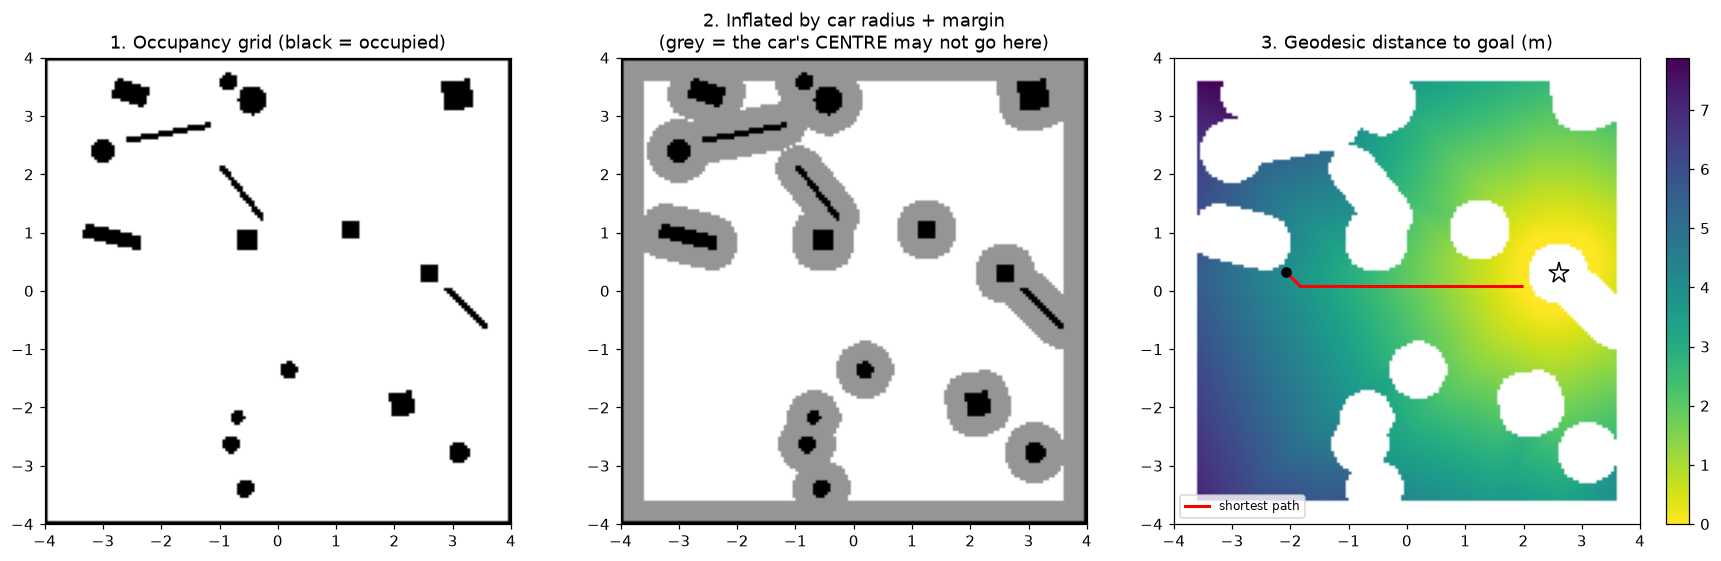

Straight-line distance start->goal centre: 4.69 m;  shortest drivable path to the success zone: 4.05 m


In [4]:
cfg = EnvConfig(); grid = Grid(cfg)
spec = sample_episode(0)
occ = occupancy(grid, spec.objects, spec.obstacles)
g_shape, _c, gx, gy = spec.goal
dist, blocked = geodesic_field(grid, occ, g_shape, gx, gy)
h = cfg.arena_size / 2; ext = (-h, h, -h, h)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(occ.T, origin="lower", extent=ext, cmap="Greys"); axes[0].set_title("1. Occupancy grid (black = occupied)")
axes[1].imshow((blocked & ~occ).T * 0.5 + occ.T, origin="lower", extent=ext, cmap="Greys", vmax=1)
axes[1].set_title("2. Inflated by car radius + margin\n(grey = the car's CENTRE may not go here)")
im = axes[2].imshow(np.where(np.isfinite(dist), dist, np.nan).T, origin="lower", extent=ext, cmap="viridis_r")
p = shortest_path(grid, dist, *spec.start[:2])
axes[2].plot(p[:, 0], p[:, 1], "r-", lw=2, label="shortest path"); axes[2].plot(*spec.start[:2], "ko")
axes[2].plot(gx, gy, "w*", ms=14, mec="k"); axes[2].legend(loc="lower left", fontsize=8)
axes[2].set_title("3. Geodesic distance to goal (m)"); plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes: ax.grid(False)
plt.tight_layout(); plt.show()
straight = math.hypot(spec.start[0] - gx, spec.start[1] - gy)
print(f"Straight-line distance start->goal centre: {straight:.2f} m;  shortest drivable path to the success zone: {spec.geodesic_start:.2f} m")

## 7. Checking the *training distribution* for hidden biases

Every training example comes from `sample_episode`. If the sampler has a bias, for example red
goals appearing twice as often or goals always in the middle of the arena, the model will absorb it.
So we generate **2,000 episodes** (about 30 s, no rendering needed) and look at the statistics.

**What to look for:**
* **Goal shape/colour counts** should be roughly flat (~111 each for 18 combinations).
* **Visible fraction ≈ 50%**, **hard-distractor fraction ≈ 50%**.
* **Start and goal heatmaps** should cover the arena evenly (apart from the margin near the walls).
* **Detour factor** (path length ÷ straight-line distance): mostly near 1, with a tail of episodes
  where obstacles force a real detour. That tail is where obstacle avoidance gets learned.

Sampled 2000 episodes in 30.5 s


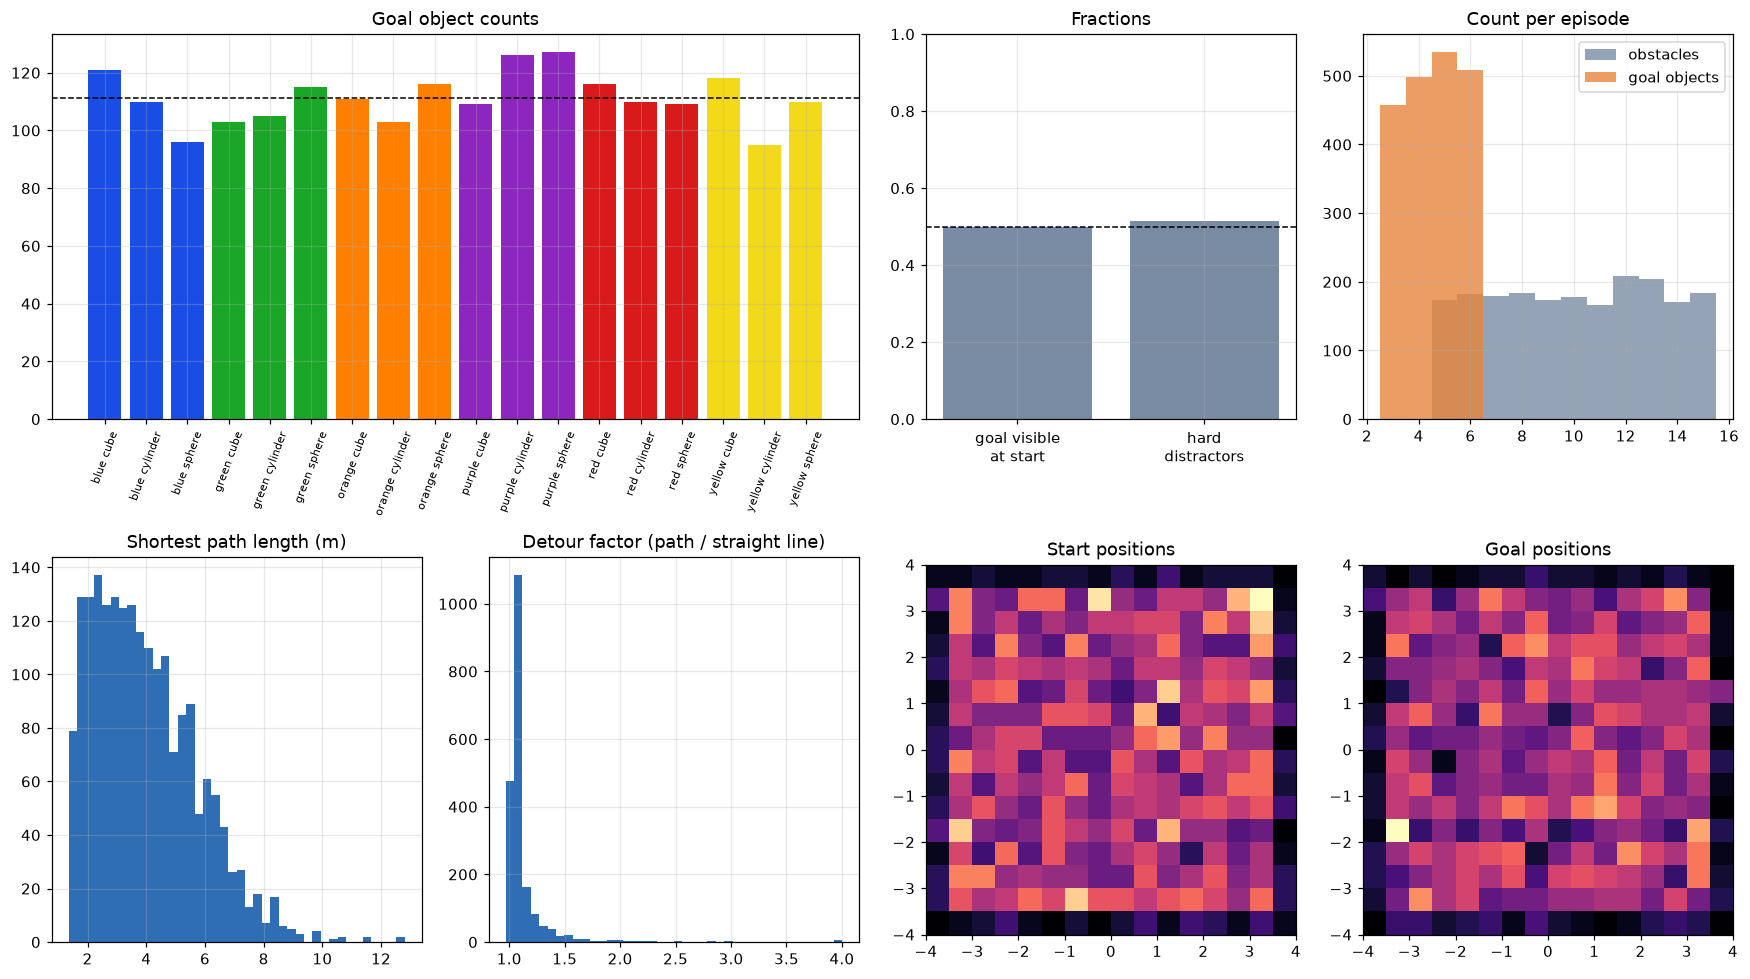

In [5]:
t = time.perf_counter()
specs = [sample_episode(10_000 + s) for s in range(2000)]
print(f"Sampled {len(specs)} episodes in {time.perf_counter() - t:.1f} s")

goal_counts = {}
for s in specs:
    goal_counts[s.goal_name] = goal_counts.get(s.goal_name, 0) + 1
geo = np.array([s.geodesic_start for s in specs])
straight = np.array([max(math.hypot(s.start[0] - s.goal[2], s.start[1] - s.goal[3]) - 0.65, 0.05) for s in specs])

fig = plt.figure(figsize=(16, 9)); gsp = fig.add_gridspec(2, 4)
ax = fig.add_subplot(gsp[0, :2])
names = sorted(goal_counts); ax.bar(range(len(names)), [goal_counts[n] for n in names],
       color=[COLORS[n.split()[0]] for n in names])
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=70, fontsize=7); ax.set_title("Goal object counts")
ax.axhline(len(specs) / 18, color="k", ls="--", lw=1)
ax = fig.add_subplot(gsp[0, 2])
ax.bar(["goal visible\nat start", "hard\ndistractors"], [np.mean([s.start_visible for s in specs]), np.mean([s.hard_distractors for s in specs])], color="#7a8ca3")
ax.set_ylim(0, 1); ax.axhline(0.5, color="k", ls="--", lw=1); ax.set_title("Fractions")
ax = fig.add_subplot(gsp[0, 3])
ax.hist([len(s.obstacles) for s in specs], bins=np.arange(4.5, 16.5), color="#7a8ca3", alpha=0.8, label="obstacles")
ax.hist([len(s.objects) for s in specs], bins=np.arange(2.5, 7.5), color="#e8853d", alpha=0.8, label="goal objects")
ax.legend(); ax.set_title("Count per episode")
ax = fig.add_subplot(gsp[1, 0]); ax.hist(geo, bins=40, color="#2f6db5"); ax.set_title("Shortest path length (m)")
ax = fig.add_subplot(gsp[1, 1]); ax.hist(np.clip(geo / straight, 0, 4), bins=40, color="#2f6db5"); ax.set_title("Detour factor (path / straight line)")
for k, (title, pts) in enumerate([("Start positions", [s.start[:2] for s in specs]), ("Goal positions", [s.goal[2:] for s in specs])]):
    ax = fig.add_subplot(gsp[1, 2 + k]); pts = np.array(pts)
    ax.hist2d(pts[:, 0], pts[:, 1], bins=16, range=[[-4, 4], [-4, 4]], cmap="magma"); ax.set_aspect("equal"); ax.set_title(title); ax.grid(False)
plt.tight_layout(); plt.show()

## 8. Building the simulated environment

Now we bring the episodes to life in Genesis. One limitation shapes the whole design: **after
`scene.build()`, Genesis cannot add, remove, recolour or resize objects.** So we build *pools*
once:

* all 18 goal objects (3 shapes × 6 colours),
* 16 obstacles of different shapes and sizes,
* 3 floor covers (plus the default checker floor) and 3 sets of walls.

At each `reset()`, the episode's objects are moved into the arena and everything else is
*parked* 5 m underground, invisible. The light's direction and brightness are changed directly
in the renderer. Genesis has no official API for that, so this one hack is isolated in
`NavEnv._find_light_node`.

**Ambient light** is raised from Genesis' default 0.1 to 0.3. With random light directions, the side
of an object facing the camera is often in shadow; at 0.1, a red object then looks maroon and a
yellow one olive. Colour is exactly what the model must recognise, so we keep shadows soft.

We also add an *overview camera* for the pictures in this notebook. The model never sees it.

⏳ *The build takes a few seconds (longer the very first time, while new GPU kernels compile).*

In [6]:
import genesis as gs
from carsim.env import NavEnv
t = time.perf_counter()
env = NavEnv(overview_camera_res=(960, 640))
print(f"Built in {time.perf_counter() - t:.1f} s.  Entities in the scene: {len(env.scene.entities)}"
      f"  (lighting control available: {env._light_node is not None})")

[I 11/13/26 14:22:56.398 762706] [shell.py:_shell_pop_print@25] Graphical python shell detected, using wrapped sys.stdout


Built in 3.4 s.  Entities in the scene: 51  (lighting control available: True)


### 8.1 The goal objects as the car sees them

We build a hand-made "line-up" episode: all six colours of one shape in a row, 2.3 m in front of the
car. This shows the actual FPV view at the model's resolution. Notice how few pixels a 30 cm object
covers at a few metres' distance: **about 20 pixels across**. Distant goals are small, which is one
reason searching and approaching are hard for a vision model.

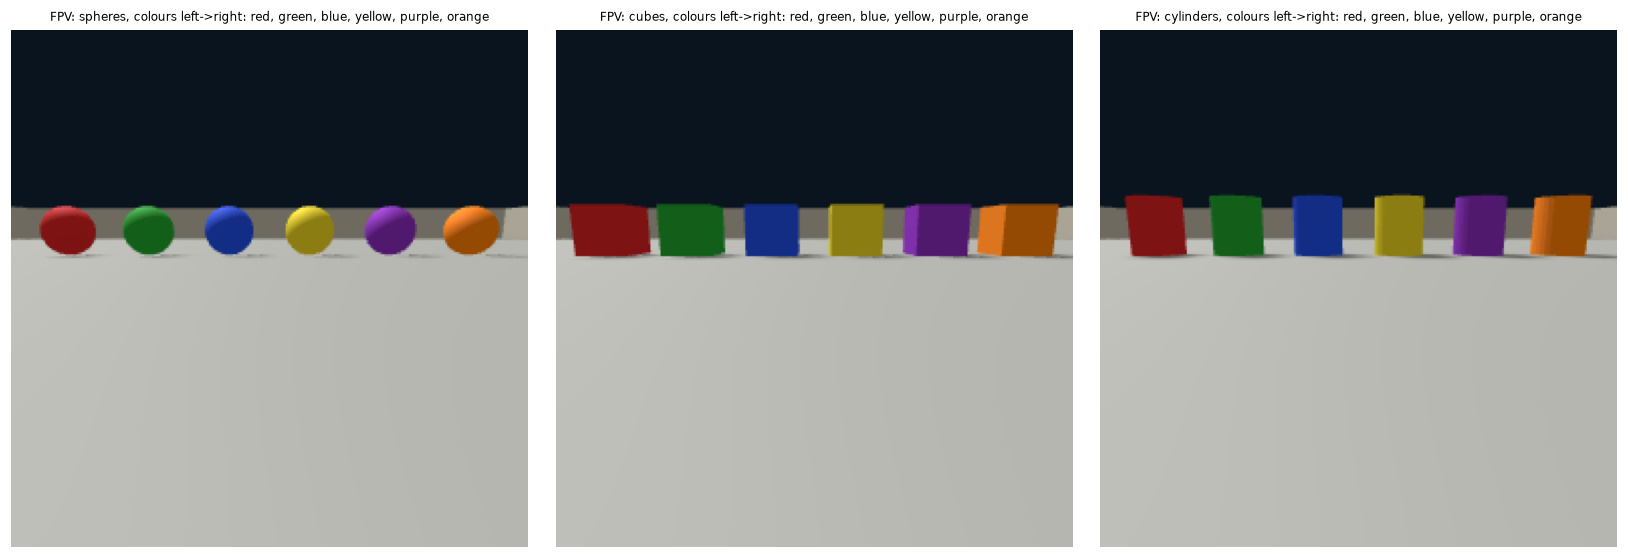

In [7]:
from carsim.world import EpisodeSpec
def lineup_spec(shape):
    objs = [(shape, c, 0.3, y) for c, y in zip(COLORS, np.linspace(1.25, -1.25, 6))]
    return EpisodeSpec(seed=-1, goal_index=0, objects=objs, obstacles=[], start=(-2.0, 0.0, 0.0),
                       prompt=f"(line-up of {shape}s)", floor_index=1, wall_index=0,
                       light={"azimuth": 0.8, "elevation": 1.0, "intensity": 5.0}, hard_distractors=False,
                       start_visible=True, geodesic_start=0.0, dist_field=np.zeros((grid.n, grid.n)))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, shape in zip(axes, SHAPES):
    obs, info = env.reset(spec=lineup_spec(shape))
    ax.imshow(obs["image"]); ax.set_title(f"FPV: {shape}s, colours left->right: " + ", ".join(COLORS), fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### 8.2 Random episodes: overview and FPV

For four random episodes we show a bird's-eye picture from the overview camera, the map, and what
the car sees at the start. Check:
* the 3-D scene matches the map;
* when the map says the goal is *visible*, you can find it in the FPV image;
* floors, wall colours and lighting vary between episodes.

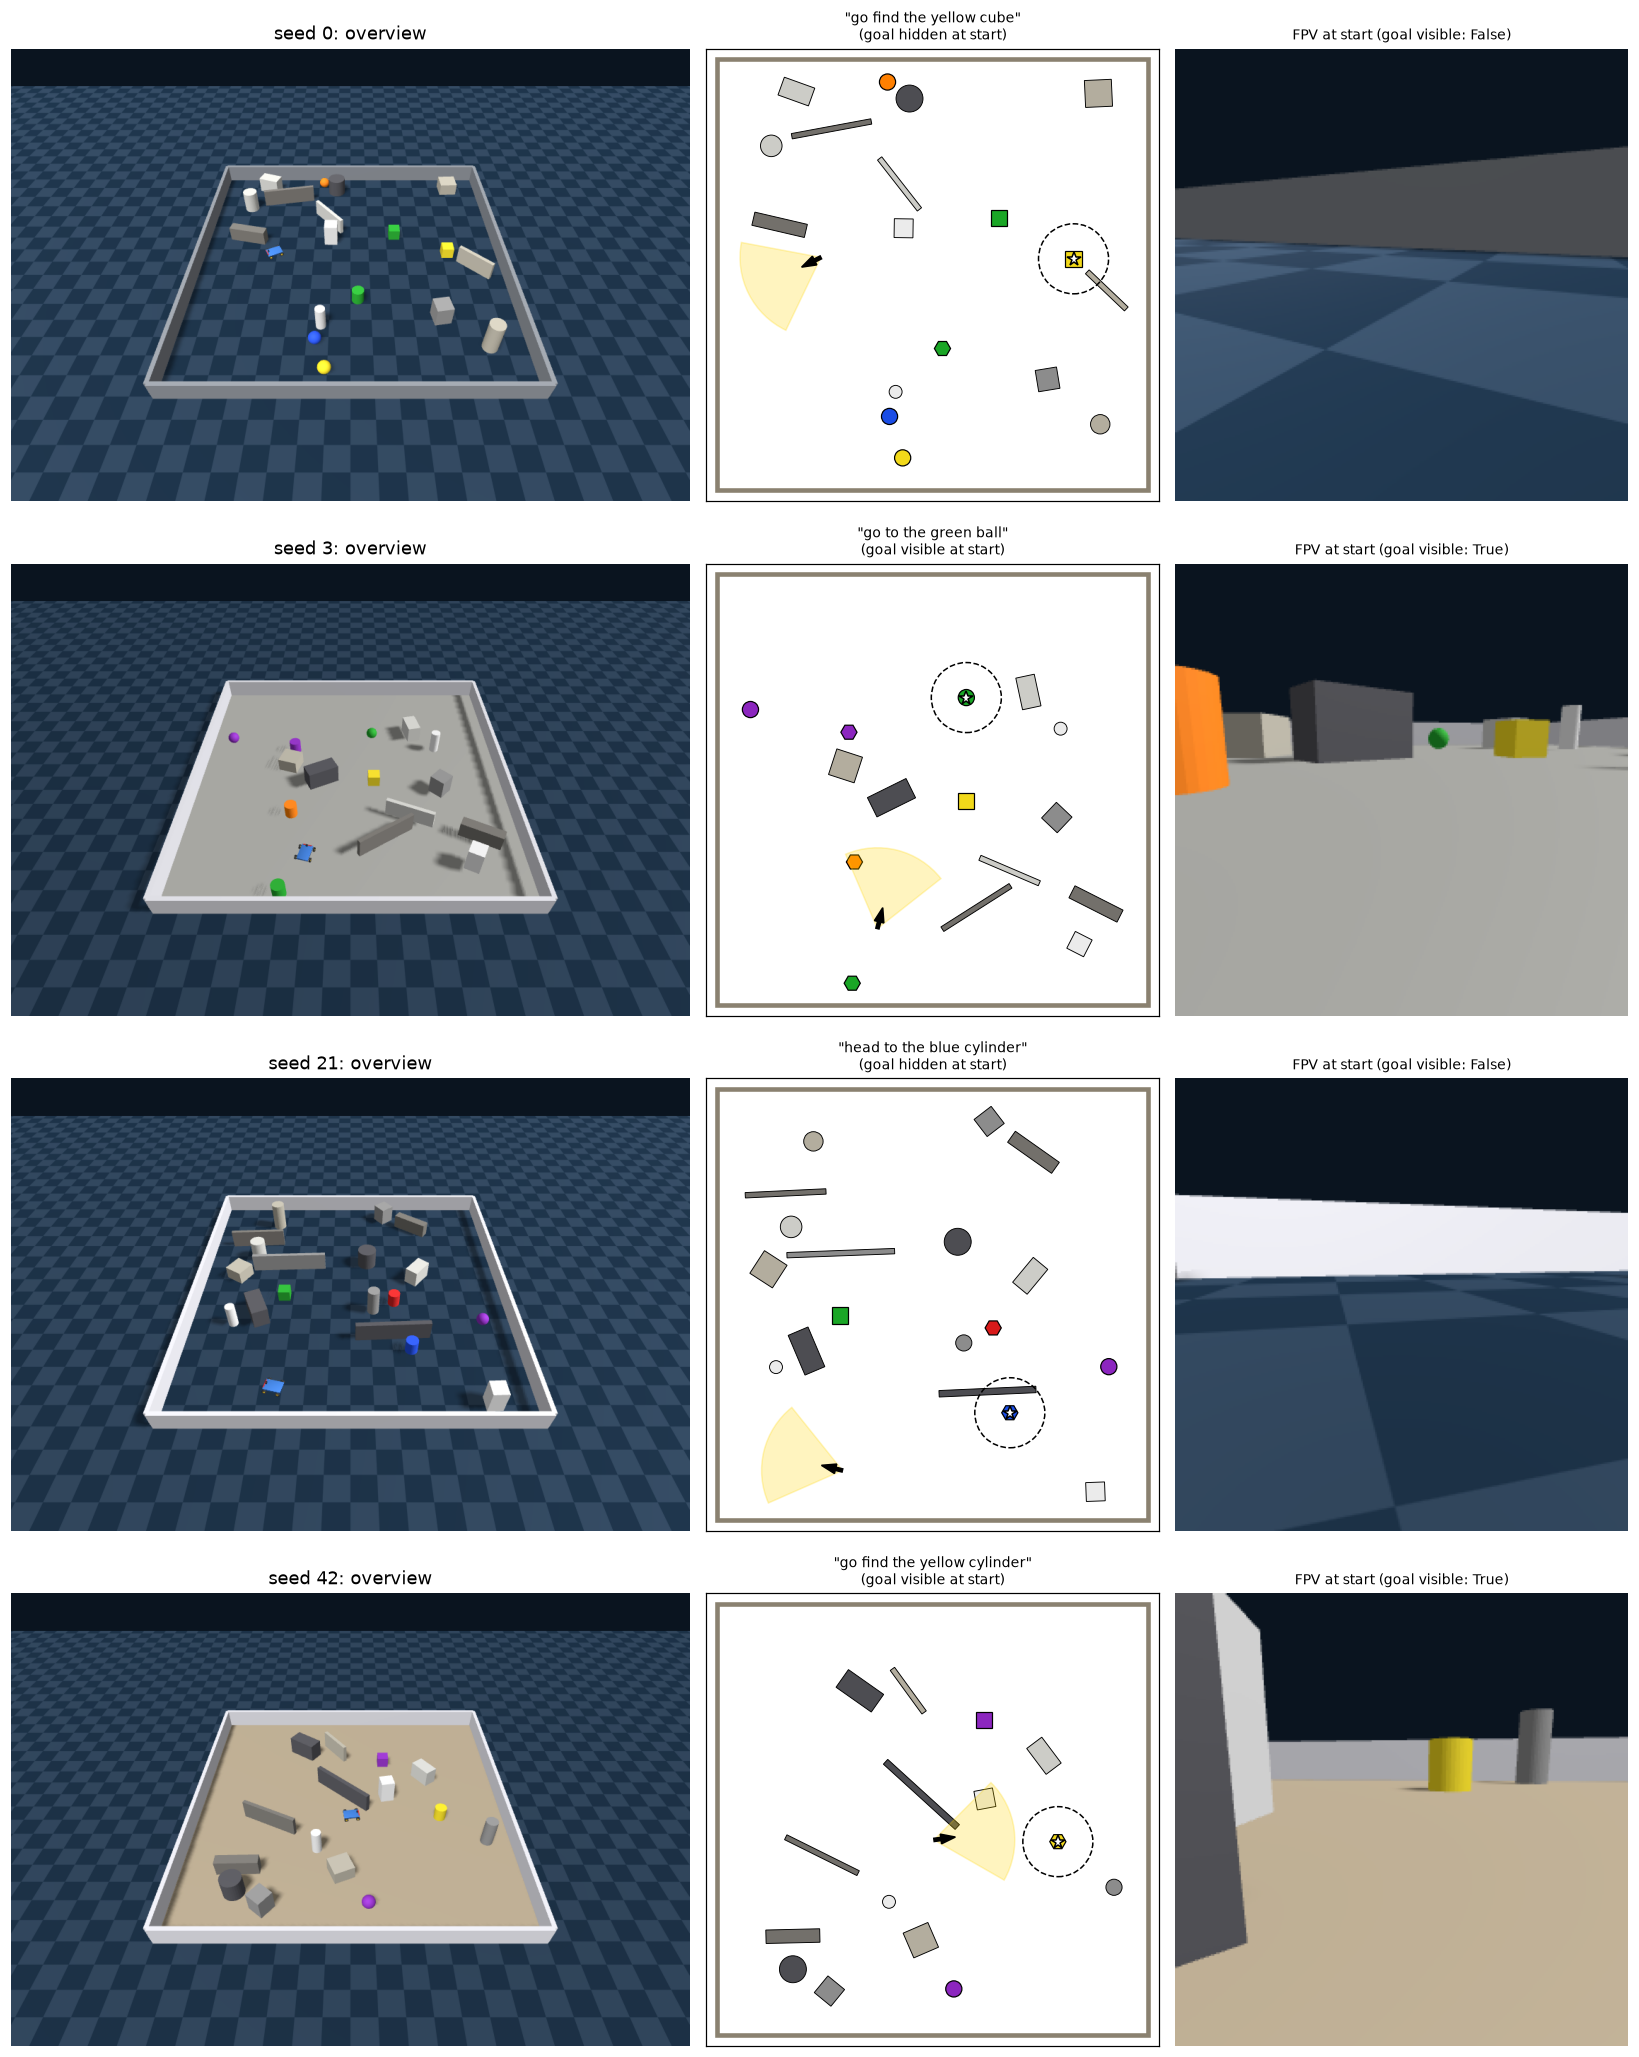

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(15, 19), gridspec_kw={"width_ratios": [1.5, 1, 1]})
for row, seed in enumerate([0, 3, 21, 42]):
    obs, info = env.reset(seed)
    axes[row, 0].imshow(env.render_overview(pos=(0, -8.5, 8.0), lookat=(0, -0.5, 0))); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"seed {seed}: overview")
    draw_episode(env.spec, ax=axes[row, 1], show_path=False)
    axes[row, 2].imshow(obs["image"]); axes[row, 2].axis("off")
    axes[row, 2].set_title(f"FPV at start (goal visible: {info['goal_visible']})", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Success and collisions

**Success** (checked every step, ends the episode):
* the car's **front bumper is within 30 cm of the goal's surface**, **and**
* the car is **almost stopped** (speed < 0.10 m/s and turning < 0.3 rad/s).

Why require stopping? "Drive to the red sphere" means *arrive and stay*, not "brush past it at full
speed". It also gives the model a clear behaviour to learn at the end of every episode: slow down
and stop.

**Collisions** are detected from Genesis contact data: after each of the 10 physics steps in a
control step, we check whether the car's body touches anything **other than the goal object**
(touching the goal gently is fine). Collisions do *not* end the episode. Your demonstrations
record them, and in notebook 02 you decide whether to keep an episode that had collisions.

**Time limit:** 60 s (600 steps). Running out is a *truncation*.

## 10. A privileged expert: testing the environment with a scripted driver

How do we know the environment works (episodes solvable, success detected, collisions detected)
without driving hundreds of episodes by hand? We write a **scripted expert** that *cheats*: it
reads the geodesic distance map and follows the shortest path. Because it uses information the
real policy never gets, it is called a **privileged** expert.

It is useful in three ways:
1. **Environment test:** if a perfect-information driver can't succeed, the episode or the success
   check is broken.
2. **Upper bound:** later, in notebooks 04 and 05, it tells us how well a driver *could* do.
3. **Optional extra data:** it could generate demonstrations automatically. But it drives
   differently from a human: it never searches, because it already knows where the goal is.

The plots show one expert episode: its path on the map, the distance to the goal over time
(geodesic and to the goal's surface), and the commands it sent. Watch the end: it turns to face
the goal and stops, and success fires.

"go to the green ball" -> success=True after 8.5 s; path 4.20 m vs shortest 4.28 m; collision steps 0


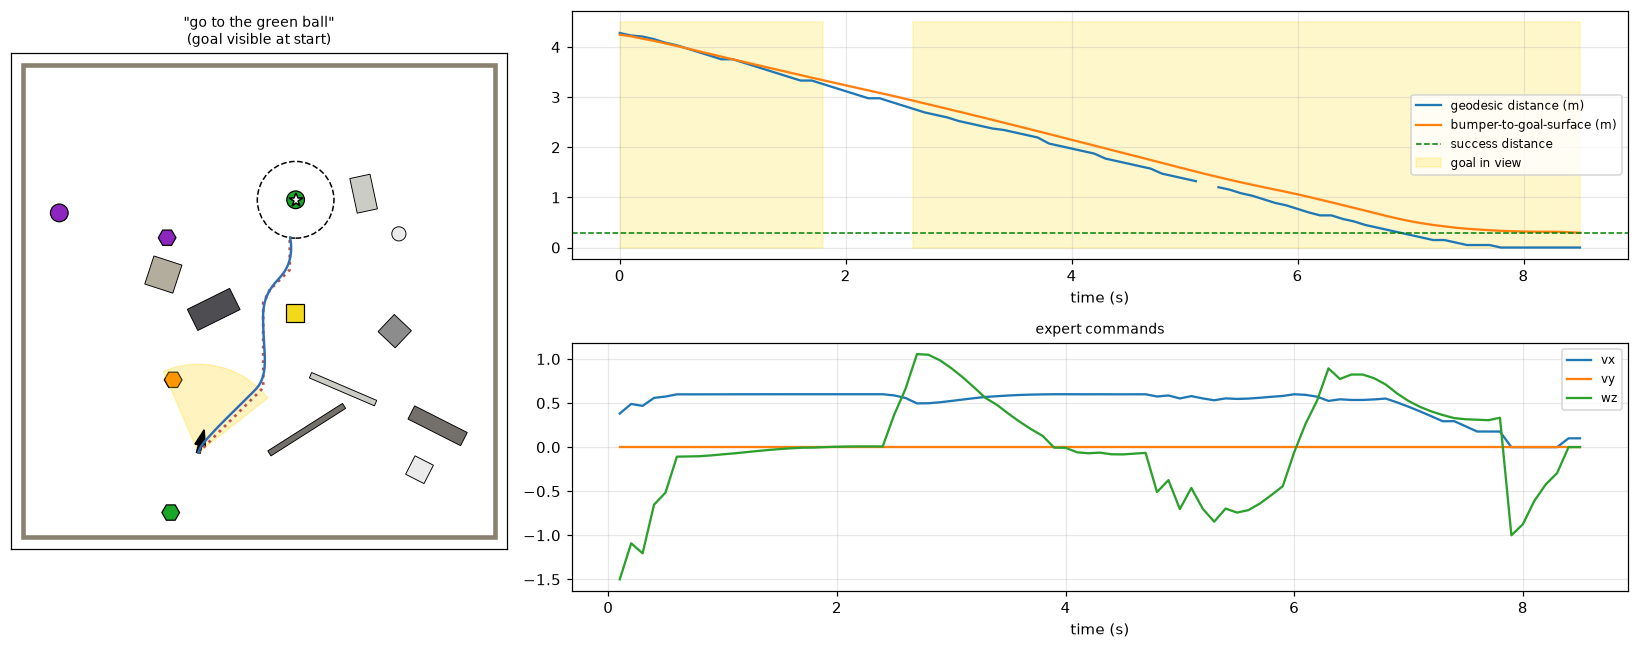

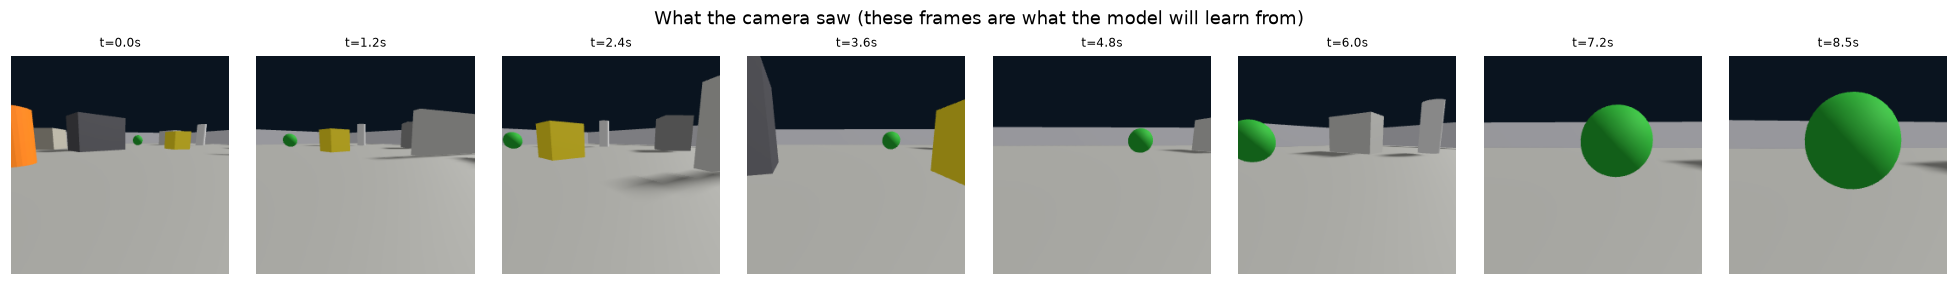

In [9]:
from carsim.expert import PathFollowingExpert
expert = PathFollowingExpert(env)

def run_episode(policy, seed):
    obs, info = env.reset(seed)
    frames, traj, cmds, infos = [obs["image"]], [info["pose"]], [], [info]
    while True:
        a = policy(info)
        obs, terminated, truncated, info = env.step(a)
        frames.append(obs["image"]); traj.append(info["pose"]); cmds.append(a); infos.append(info)
        if terminated or truncated:
            return np.array(frames), np.array(traj), np.array(cmds), infos

frames, traj, cmds, infos = run_episode(expert.act, seed=3)
last = infos[-1]
print(f'"{last["prompt"]}" -> success={last["success"]} after {last["t"] / 10:.1f} s; '
      f'path {last["path_length"]:.2f} m vs shortest {env.spec.geodesic_start:.2f} m; collision steps {last["n_collision_steps"]}')

fig = plt.figure(figsize=(15, 6)); gsp = fig.add_gridspec(2, 3)
draw_episode(env.spec, ax=fig.add_subplot(gsp[:, 0]), trajectory=traj[:, :2])
tt = np.arange(len(infos)) / 10
ax = fig.add_subplot(gsp[0, 1:])
ax.plot(tt, [i["geodesic_dist"] for i in infos], label="geodesic distance (m)")
ax.plot(tt, [i["goal_surface_dist"] for i in infos], label="bumper-to-goal-surface (m)")
ax.axhline(env.cfg.success_dist, color="g", ls="--", lw=1, label="success distance")
vis = np.array([i["goal_visible"] for i in infos])
ax.fill_between(tt, 0, ax.get_ylim()[1], where=vis, color="gold", alpha=0.2, label="goal in view")
ax.legend(fontsize=8); ax.set_xlabel("time (s)")
ax = fig.add_subplot(gsp[1, 1:])
for k, n in enumerate(["vx", "vy", "wz"]):
    ax.plot(tt[1:], cmds[:, k], label=n)
ax.legend(fontsize=8); ax.set_xlabel("time (s)"); ax.set_title("expert commands", fontsize=9)
plt.tight_layout(); plt.show()

idx = np.linspace(0, len(frames) - 1, 8).astype(int)
fig, axes = plt.subplots(1, 8, figsize=(18, 2.6))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i]); ax.set_title(f"t={i / 10:.1f}s", fontsize=8); ax.axis("off")
plt.suptitle("What the camera saw (these frames are what the model will learn from)"); plt.tight_layout(); plt.show()

### 10.1 Expert on 50 episodes: environment health check

The metrics here are the same ones we will use to judge our trained model:

* **Success rate**: fraction of episodes that ended in success.
* **SPL (Success weighted by Path Length)**: $\text{SPL} = \frac{1}{N}\sum_i S_i \frac{\ell_i}{\max(p_i, \ell_i)}$,
  where $S_i$ is 1 for success, $\ell_i$ the shortest path and $p_i$ the path actually driven. A perfect
  driver scores 1.0; wandering around lowers it, and failure scores 0.
* **Collision rate**: fraction of episodes with at least one collision.

**What I expect, and what we got when I built this:** the expert succeeds in roughly 95–100% of
episodes. It is *not* perfect: once in a while it circles an obstacle near the goal and times out.
That's fine, because it is a test tool, not our policy. What matters: success detection fires,
the episodes are solvable, and collisions are rare and short.

⏳ About 1–2 minutes.

Ran 50 episodes in 72 s


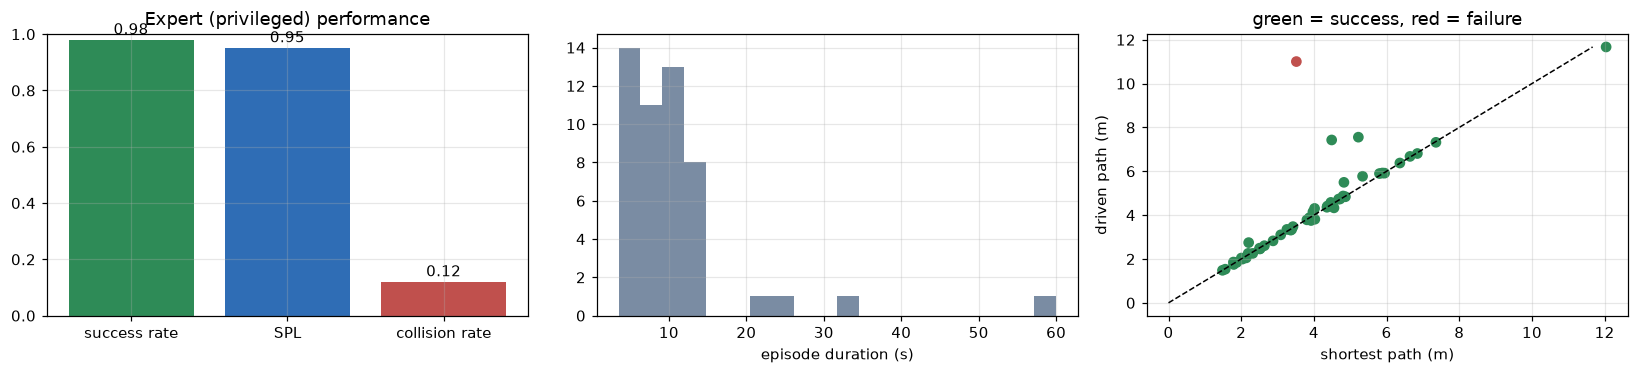

In [10]:
results = []
t = time.perf_counter()
for seed in range(500, 550):
    _, traj_, _, infos_ = run_episode(expert.act, seed)
    L = infos_[-1]
    results.append(dict(success=L["success"], steps=L["t"], coll=L["n_collision_steps"] > 0,
                        path=L["path_length"], shortest=env.spec.geodesic_start))
print(f"Ran 50 episodes in {time.perf_counter() - t:.0f} s")
succ = np.array([r["success"] for r in results]); coll = np.array([r["coll"] for r in results])
spl = np.mean([r["success"] * r["shortest"] / max(r["path"], r["shortest"]) for r in results])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].bar(["success rate", "SPL", "collision rate"], [succ.mean(), spl, coll.mean()], color=["#2e8b57", "#2f6db5", "#c0504d"])
axes[0].set_ylim(0, 1); axes[0].set_title("Expert (privileged) performance")
for i, v in enumerate([succ.mean(), spl, coll.mean()]): axes[0].text(i, v + 0.02, f"{v:.2f}", ha="center")
axes[1].hist([r["steps"] / 10 for r in results], bins=20, color="#7a8ca3"); axes[1].set_xlabel("episode duration (s)")
axes[2].scatter([r["shortest"] for r in results], [r["path"] for r in results], c=np.where(succ, "#2e8b57", "#c0504d"))
m = max(r["path"] for r in results); axes[2].plot([0, m], [0, m], "k--", lw=1)
axes[2].set_xlabel("shortest path (m)"); axes[2].set_ylabel("driven path (m)"); axes[2].set_title("green = success, red = failure")
plt.tight_layout(); plt.show()

## 11. Your turn: drive some episodes 🎮

The driving program now uses the full environment. Every episode is a new random layout, and
the **goal prompt is shown at the top of the FPV window**.

| Key | Action |
|---|---|
| ↑ / ↓ | forward / backward |
| ← / → | rotate left / right |
| Q / E | strafe left / right |
| Space | stop |
| R | restart the same episode |
| N | skip to a new episode |
| Esc | quit |

The FPV window shows the distance to the goal, a timer and a collision counter. A **red border**
flashes on a collision. Reach the goal and **stop**: "SUCCESS!" appears and a new episode starts.

Try 5–10 episodes. Pay attention to how *you* search when the goal starts out of view: do you
rotate on the spot, or drive and look around? That is the behaviour the model will copy.
**Hint:** a clear, consistent driving style makes better training data than a fast, erratic one.

In [ ]:
import subprocess
drive_log_path = RUNS / "env_drive.npz"
result = subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "teleop.py"), "--log", str(drive_log_path)],
                        cwd=PROJECT_ROOT, capture_output=True, text=True)
print("\n".join(l for l in result.stdout.splitlines() if l.strip()))
if result.returncode != 0:
    print("Teleop exited with an error:\n", result.stderr[-2000:])

### 11.1 Your episodes vs. the shortest path

Each episode is rebuilt from its seed, so we can draw your path on the map next to the shortest
path. If you found the goal efficiently, the two lines are close. When the goal started hidden,
expect a search phase first.

In [3]:
drive_log_path = RUNS / "env_drive.npz"     # written by the driving cell above
if not drive_log_path.exists():
    print("No drive log yet - run the teleop cell above first.")
else:
    d = np.load(drive_log_path)
    episodes = np.unique(d["episode"])
    n = min(len(episodes), 6)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), squeeze=False)
    for ax, ep in zip(axes[0], episodes[-n:]):
        m = d["episode"] == ep
        spec_ep = sample_episode(int(d["seed"][m][0]))
        draw_episode(spec_ep, ax=ax, trajectory=d["pose"][m][:, :2],
                     title=f'"{spec_ep.prompt}"\n{m.sum() / 10:.1f} s driven')
    axes[0][0].legend(fontsize=7, loc="lower left")
    plt.tight_layout(); plt.show()

No drive log yet - run the teleop cell above first.


## 12. Summary and next step

**What we built:**
- ✅ A random episode generator with 18 goal objects, word-sharing distractors, neutral obstacles,
  a 50/50 visible/hidden start and varied looks, with every episode solvable and reproducible from a seed.
- ✅ Grid planning (inflation + Dijkstra), giving a *geodesic distance map* for rewards and metrics later.
- ✅ A Genesis environment with a Gymnasium-style `reset`/`step` interface, and success and
  collision detection.
- ✅ A privileged expert driver that validates the environment and gives an upper-bound baseline.

**Next: notebook 02, recording demonstrations.** You will learn the LeRobot dataset format, record a few drives
yourself to see how demonstrations are made, and then let a scripted driver record the 300 drives that the model
is trained on.